In [86]:
import pandas as pd 
import numpy as np 
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score ,mean_absolute_error
from sklearn.pipeline import Pipeline

In [87]:
df=pd.read_csv("House Price Prediction Dataset.csv")

In [111]:
df.head()

,Id,Area,Bedrooms,Bathrooms,Floors,YearBuilt,Location,Condition,Garage,Price
0,1,1360,5,4,3,1970,Downtown,Excellent,No,149919
1,2,4272,5,4,3,1958,Downtown,Excellent,No,424998
2,3,3592,2,2,3,1938,Downtown,Good,No,266746
3,4,966,4,2,2,1902,Suburban,Fair,Yes,244020
4,5,4926,1,4,2,1975,Downtown,Fair,Yes,636056


In [88]:
X=df.drop(columns=["Id","Price"])
y=df["Price"]

In [112]:
cate=['Location','Condition','Garage']
numb=['Area','Bathrooms','Floors','YearBuilt','Bedrooms']

In [113]:
preprocess= ColumnTransformer(
    transformers=[
    ('num','passthrough',numb),
    ('cat',OneHotEncoder(handle_unknown='ignore'),cate)
])

In [114]:
model_p=Pipeline(steps=[
    ('preprocessor',preprocess),
    ('regressor',RandomForestRegressor(n_estimators=100,random_state=42))
])

In [115]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42)

In [116]:
print("Unique locations:", df['Location'].unique())
print("Unique conditions:", df['Condition'].unique())
print("Unique garages:", df['Garage'].unique())

# Let's inspect the columns in our feature set X
print("Features list:", X.columns.tolist())

Unique locations: <StringArray>
['Downtown', 'Suburban', 'Urban', 'Rural']
Length: 4, dtype: str
Unique conditions: <StringArray>
['Excellent', 'Good', 'Fair', 'Poor']
Length: 4, dtype: str
Unique garages: <StringArray>
['No', 'Yes']
Length: 2, dtype: str
Features list: ['Area', 'Bedrooms', 'Bathrooms', 'Floors', 'YearBuilt', 'Location', 'Condition', 'Garage']


In [117]:
model_p.fit(X_train,y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('regressor', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](8,)","['Area','Bedrooms','Bathrooms',...,'Location','Condition','Garage']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,8
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis

In [123]:
y_pred = model_p.predict(X_test)
mae=mean_absolute_error(y_test,y_pred)
r2=r2_score(y_test,y_pred)

In [122]:
print(f"Model trained successfully!")
print(f"Mean Absolute Error on Test Set: ${mae:,.2f}")
print(f"R-squared Score on Test Set: {r2:.4f}")

Model trained successfully!
Mean Absolute Error on Test Set: $254,445.46
R-squared Score on Test Set: -0.1125


In [139]:
Area = 2500                     #@param {type:"number"}
Bedrooms = 2                    #@param {type:"slider", min:1, max:10, step:1}
Bathrooms = 1                   #@param {type:"slider", min:1, max:8, step:1}
Floors = 2                      #@param {type:"slider", min:1, max:4, step:1}
YearBuilt = 20005                #@param {type:"integer"}
Location = "Downtown"           #@param ["Downtown", "Suburban", "Rural"]
Condition = "Fair"              #@param ["Excellent", "Good", "Fair", "Poor"]
Garage = "Yes"                  #@param ["Yes", "No"]


input_data = pd.DataFrame([{
    'Area': Area,
    'Bedrooms': Bedrooms,
    'Bathrooms': Bathrooms,
    'Floors': Floors,
    'YearBuilt': YearBuilt,
    'Location': Location,
    'Condition': Condition,
    'Garage': Garage
}])

predicted_price = model_p.predict(input_data)[0]

print("-------------------------------------------")
print(f"Estimated House Price: ${predicted_price:,.2f}")
print("-------------------------------------------")

-------------------------------------------
Estimated House Price: $557,873.76
-------------------------------------------


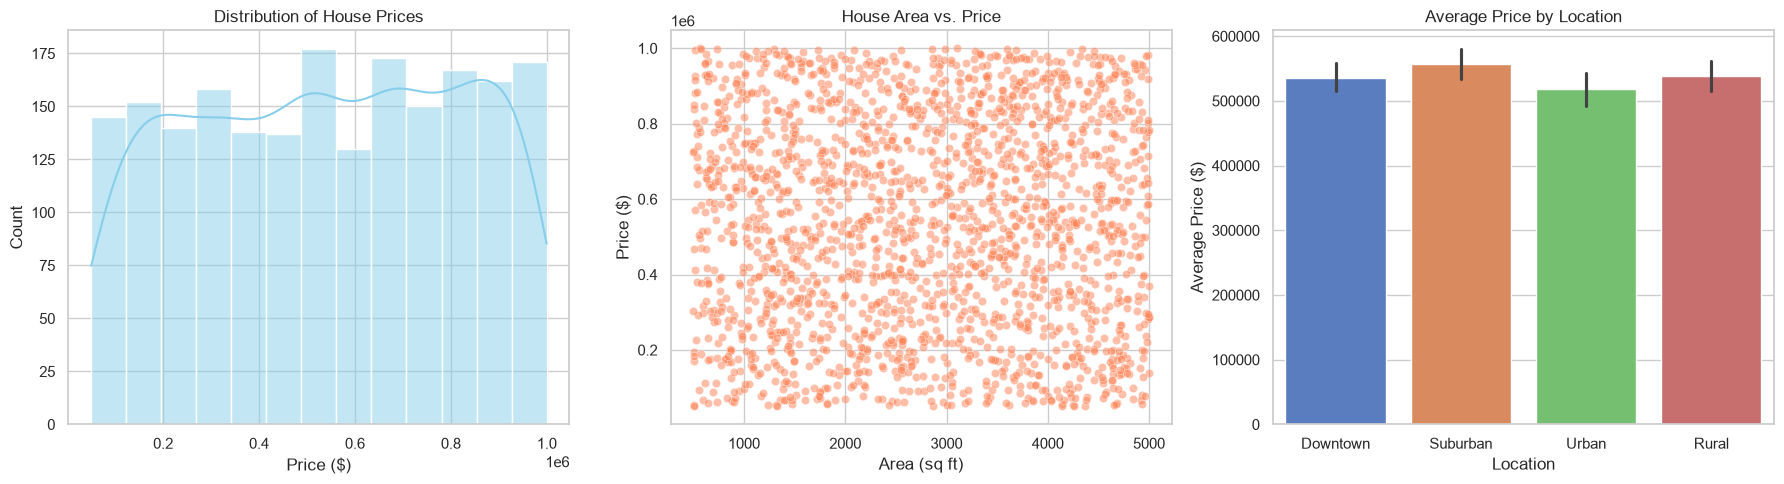

In [140]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set up the plotting environment
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Distribution of House Prices
sns.histplot(df['Price'], kde=True, ax=axes[0], color='skyblue')
axes[0].set_title('Distribution of House Prices')
axes[0].set_xlabel('Price ($)')
axes[0].set_ylabel('Count')

# 2. Relationship between Area and Price
sns.scatterplot(data=df, x='Area', y='Price', alpha=0.5, ax=axes[1], color='coral')
axes[1].set_title('House Area vs. Price')
axes[1].set_xlabel('Area (sq ft)')
axes[1].set_ylabel('Price ($)')

# 3. Average Price by Location
sns.barplot(data=df, x='Location', y='Price', ax=axes[2], palette='muted', hue='Location', legend=False)
axes[2].set_title('Average Price by Location')
axes[2].set_xlabel('Location')
axes[2].set_ylabel('Average Price ($)')

plt.tight_layout()
plt.show()